# Assignment 4

In [1]:
# Import the necessary libraries
import matplotlib.pyplot as plt
import numpy as np
import time
import ipywidgets as widgets
from IPython.display import display

In [2]:
BOOK_PATH = "goblet_book.txt"

## Data Handler Class

In [ ]:
class DataHandler:
    """
    Class for data management.

    Args:
        file_name: The name of the file to read.
    Attributes:
        data: The data read from the file.
        data_vector: A list of unique characters in the data.
        K: Dim. of the data (length of data_vector).
    """

    def __init__(self, file_name):

        # Load data:
        try:
            with open(file_name, "r", encoding="utf-8") as fid:
                self.data = fid.read()
        except FileNotFoundError:
            raise FileNotFoundError(f"Could not find file: {file_name}")
        
        # Store characters, length and dimension
        self.data_vector = sorted(list(set(self.data)))
        self.K = len(self.data_vector)
        self.N = len(self.data)

        # Create fast lookup dictionaries
        self.char_to_ind_dict = {char: ind for ind, char in enumerate(self.data_vector)}
        self.ind_to_char_dict = {ind: char for ind, char in enumerate(self.data_vector)}

        # Prepare a rng (which will likely be updated by network later)
        self.rng = np.random.default_rng()
        
        # Print status
        print(f"DataHandler: Loaded file {file_name} with dimension {self.K} of length {self.N}.")

    def char_to_ind(self, char):
        """
        Convert a character to an index based on the dict. char_to_ind_dict.

        Args:
            char: The character to convert.
        Returns:
            The index of the character in the data vector.
        """
        return self.char_to_ind_dict[char]
    
    def sec_to_one_hot(self, sec):
        seq_len = len(sec)
        one_hot = np.zeros((self.K, seq_len))
        indices = [self.char_to_ind_dict[c] for c in sec]
        one_hot[indices, np.arange(seq_len)] = 1
        return one_hot

    def ind_to_char(self, ind):
        """
        Convert an index to a character based on the dict. ind_to_char_dict.

        Args:
            ind: The index to convert.
        Returns:
            The character corresponding to the index in the data vector.
        """
        return self.ind_to_char_dict[ind]
    
    def get_input_seq(self, e, seq_length):
        return self.data[e:e+seq_length]
    
    def get_target_seq(self, e, seq_length):
        return self.data[e+1 : e+seq_length+1]
    
    def get_target_indices(self, e, seq_length):
        raw_str = self.get_target_seq(e, seq_length)
        return np.array([self.char_to_ind_dict[c] for c in raw_str])
    
    # Note that the following two functions should be possible
    # to combine and make shorter...
    def get_input_seq_one_hot(self, e, seq_length):
        return self.sec_to_one_hot(self.get_input_seq(e, seq_length))
    
    def get_target_seq_one_hot(self, e, seq_length):
        return self.sec_to_one_hot(self.get_target_seq(e, seq_length))

    def get_random_char_one_hot(self):
        random_char = self.rng.choice(self.data_vector)
        return self.sec_to_one_hot(random_char)

We explore the data a bit before continuing...

In [4]:
data_handler = DataHandler(BOOK_PATH)
print(f"data_vector: {data_handler.data_vector}")
print(f"char_to_ind_dict: {data_handler.char_to_ind_dict}")
print(f"ind_to_char_dict: {data_handler.ind_to_char_dict}")

DataHandler: Loaded file goblet_book.txt with dimension 80 of length 1107542.
data_vector: ['N', 'n', '?', 'z', '!', 'f', '^', 'T', 'i', '(', ' ', 'D', 's', 't', 'V', 'O', 'g', 'p', 'u', '.', 'a', 'l', 'd', ':', 'S', 'w', 'r', "'", 'L', 'B', '}', '"', 'v', '2', 'k', 'P', '0', 'M', 'o', '1', '7', '\t', '\n', 'J', 'H', 'A', 'C', 'Z', 'F', '_', 'h', 'b', 'm', ',', '4', 'Q', 'e', 'X', 'q', '3', 'U', ')', '6', '•', 'c', ';', 'I', 'Y', 'ü', 'E', '/', '-', 'R', '9', 'K', 'j', 'G', 'y', 'x', 'W']
char_to_ind_dict: {'N': 0, 'n': 1, '?': 2, 'z': 3, '!': 4, 'f': 5, '^': 6, 'T': 7, 'i': 8, '(': 9, ' ': 10, 'D': 11, 's': 12, 't': 13, 'V': 14, 'O': 15, 'g': 16, 'p': 17, 'u': 18, '.': 19, 'a': 20, 'l': 21, 'd': 22, ':': 23, 'S': 24, 'w': 25, 'r': 26, "'": 27, 'L': 28, 'B': 29, '}': 30, '"': 31, 'v': 32, '2': 33, 'k': 34, 'P': 35, '0': 36, 'M': 37, 'o': 38, '1': 39, '7': 40, '\t': 41, '\n': 42, 'J': 43, 'H': 44, 'A': 45, 'C': 46, 'Z': 47, 'F': 48, '_': 49, 'h': 50, 'b': 51, 'm': 52, ',': 53, '4': 54, 

## Neural Network Class

In [5]:
class Activation:
    @staticmethod
    def softmax(X):
        """
        Softmax activation function.

        Args:
            X: Input array of shape (K, N)
        Returns:
            Output array of shape (K, N)
        """
        exp_Z = np.exp(X - np.max(X, axis=0, keepdims=True))
        return exp_Z / np.sum(exp_Z, axis=0, keepdims=True)
    @staticmethod
    def softmax_derivative(**kwargs):
        """
        Args:
            X: Input array (pre-activation scores)
            Y: One-hot-encoded labels
        Returns:
            P - Y (the proper gradient for cross-entropy + softmax)
        """
        X = kwargs['X']
        Y = kwargs['Y']
        P = Activation.softmax(X)
        return P - Y  # Return P - Y_labels directly
    
    @staticmethod
    def tahn(X):
        """
        Tanh activation function.

        Args:
            X: Input array of shape (d, N)
        Returns:
            Output array of shape (d, N)
        """
        return np.tanh(X)
    @staticmethod
    def tahn_derivative(**kwargs):
        """
        Tanh derivative function.

        Source: https://medium.com/@vikrampande783/derivative-of-sigmoid-and-tanh-ffdea6efb464

        Args:
            G: Incoming gradient of shape (d, N)
            Y: Input array of shape (d, N) holding layer output
        Returns:
            Output array of shape (d, N)
        """
        G = kwargs['G']
        Y = kwargs['Y']
        return G * (1 - Y**2)

In [6]:
class Layer:

    def __init__(self, net, lam, activation):
        self.prev_layer = None
        self.next_layer = None

        self.net = net
        self.lam = lam

        self.X = []
        self.Y = []
        self.Z = []

        self.G = None # Holds gradients to be passed to upper layer

        if activation == "softmax":
            self.activation_func = Activation.softmax
            self.activation_func_derivative = Activation.softmax_derivative
        elif activation == "tanh":
            self.activation_func = Activation.tahn
            self.activation_func_derivative = Activation.tahn_derivative
        else:
            raise(f"Unsupported activation detected.")

    def update_params(self, eta):
        pass

    def clear(self):
        pass

    def get_X(self):
        return self.X[-1] if isinstance(self.X, list) else self.X
    def get_first_X(self):
        return self.X[0] if isinstance(self.X, list) else self.X
    
    def get_Y(self):
        return self.Y[-1] if isinstance(self.Y, list) else self.Y
    def get_first_Y(self):
        return self.Y[0] if isinstance(self.Y, list) else self.Y
    
    def get_Z(self):
        if len(self.Z) == 0:
            return None
        return self.Z[-1] if isinstance(self.Z, list) else self.Z

In [7]:
class FullyConnectedLayer(Layer):
    def __init__(self, net, d, m, activation, lam = 0.):
        """
        Initializes the fully connected layer using He initilization
        for both weights and biases.

        Args:
            net: The neural network to which this layer belongs
            d: Input dim. (num. of features)
            m: Num. of neurons in the hidden layer
            activation: The activation function to use
            lam: Regularization strength
        """
        super().__init__(net, lam, activation)

        self.W = (1/np.sqrt(m))*self.net.rng.standard_normal(size = (m, d)) # He initialization
        self.b = np.zeros((m, 1))

        self.grad_W = \
        self.grad_b = None

    def clear(self, **kwargs):
        self.X = []
        self.Y = []
        self.Z = []

    def forward(self, X = None, save_state=True):
        """
        Forward pass.   

        Args:
            X: Input data of shape (d, N)
        """
        if X is None and save_state:
            X = self.prev_layer.get_Z()

        # Store X, Y, Z
        Y = self.W @ X + self.b
        Z = self.activation_func(Y)
        if save_state:
            self.X.append(X)
            self.Y.append(Y)
            self.Z.append(Z)
        return Z
    
    def backward(self, Y):
        # Get time steps and prepare grad. arrays
        T = len(self.X)
        self.grad_W = np.zeros_like(self.W)
        self.grad_b = np.zeros_like(self.b)
        
        # And a list of grads (dL/dht) for each timestep to pass
        G = [None] * T # List to store dL/dht for each timestep

        # Go trough time
        for t in range(T):

            # Get predicted pt and yt
            y_t = Y[:, t:t+1]
            
            # Calc. gradient
            g_t = self.activation_func_derivative(X = self.Y[t], Y = y_t)
            
            # Adjust weight and bias gradients
            self.grad_W += g_t @ self.X[t].T
            self.grad_b += g_t
            
            # Compute dL/dh_t to pass back to next layer
            G[t] = self.W.T @ g_t

        # Average gradients over time steps and store grads.
        self.grad_W /= T
        self.grad_b /= T
        self.G = G
    
    def update_params(self, eta):
        """
        Updates the weights and biases using the computed gradients.

        Args:
            eta: Learning rate
        """
        self.W -= eta * self.grad_W
        self.b -= eta * self.grad_b

    def update_params_adam(self, eta, t):
        """
        Updates the weights and biases using the computed gradients.

        Args:
            eta: Learning rate
        """
        beta1 = 0.9
        beta2 = 0.999

        if not hasattr(self, "W_m"):
            self.W_m = np.zeros_like(self.W)
            self.W_v = np.zeros_like(self.W)
        
            self.b_m = np.zeros_like(self.b)
            self.b_v = np.zeros_like(self.b)

        # Weight updates
        # Update bias moment estimate
        self.W_m = beta1 * self.W_m + (1 - beta1) * self.grad_W
        self.W_v = beta2 * self.W_v + (1 - beta2) * (self.grad_W**2)
        # Compute the bias corrected estimate
        w_m_hat = self.W_m / (1 - beta1**t)
        w_v_hat = self.W_v / (1 - beta2**t)
        # Update params
        self.W -= eta * w_m_hat / (np.sqrt(w_v_hat) + 1e-8)

        # Bias updates
        # Update bias moment estimate
        self.b_m = beta1 * self.b_m + (1 - beta1) * self.grad_b
        self.b_v = beta2 * self.b_v + (1 - beta2) * (self.grad_b**2)
        # Compute the bias corrected estimate
        b_m_hat = self.b_m / (1 - beta1**t)
        b_v_hat = self.b_v / (1 - beta2**t)
        # Update params
        self.b -= eta * b_m_hat / (np.sqrt(b_v_hat) + 1e-8)

In [8]:
class RecurrentLayer(Layer):
    def __init__(self, net, K, m, activation, lam = 0.):
        """
        Initializes the recurrent layer.

        Args:
            net: The parent network
            K: Input dim. (num. of features)
            m: Num. of neurons in the hidden layer
            activation: The activation function to use
            lam: Regularization strength
        """
        super().__init__(net, lam, activation)

        self.W = (1/np.sqrt(2*m))*self.net.rng.standard_normal(size = (m, m))
        self.U = (1/np.sqrt(2*K))*self.net.rng.standard_normal(size = (m, K))
        self.b = np.zeros((m, 1))

        self.grad_W = np.zeros((m, m))
        self.grad_U = np.zeros((m, K))
        self.grad_b = np.zeros((m, 1))

    def clear(self, force = False):
        # Save the very last hidden state
        h_last = self.Z[-1] if len(self.Z) > 0 else None
        
        # Clear the histories
        self.X = []
        self.Y = []
        
        # Reset Z to only contain the last state
        if h_last is not None and force == False:
            self.Z = [h_last]
        else:
            self.Z = []

    def forward(self, X = None, h_prev=None, save_state=True):
        """
        Forward pass.

        Args:
            X: Input data of shape (K, N)

        Returns:
            Output of shape (K, N)
            Hidden state of shape (m, N)
        """

        if X is None and save_state:
            X = self.prev_layer.get_Z()

        # h_prev shape = (m, N) = Hidden neurons, num. of data entries
        if h_prev is None:
            h_prev = self.get_Z()
            if h_prev is None:
                h_prev = np.zeros((self.W.shape[0], X.shape[1]))
                if save_state:
                    self.Z.append(h_prev)

        # Calc. and store X, Y, Z
        Y = self.W @ h_prev + self.U @ X + self.b
        Z = self.activation_func(Y)
        if save_state:
            self.X.append(X)
            self.Y.append(Y)
            self.Z.append(Z)
        else:
            return Z

    def backward(self):
        # Get time steps and prepare grad. arrays
        T = len(self.X)
        self.grad_W = np.zeros_like(self.W)
        self.grad_U = np.zeros_like(self.U)
        self.grad_b = np.zeros_like(self.b)
        
        # Prepare new grad. matrix and get prev.
        G_next = np.zeros((self.W.shape[0], 1))
        G_prev = self.next_layer.G

        for t in reversed(range(T)):
            # Sum gradient from prev. layer and total
            G_t = G_prev[t] + G_next
            
            # Get. activation der.
            G_y = self.activation_func_derivative(G = G_t, Y = self.Z[t+1])
            
            # Accumulate weight gradients
            # Previous hidden state h_{t-1} is self.Z[t-1] or zero if t=0
            #z_prev = self.Z[t] if t > 0 else np.zeros_like(self.Z[0])
            z_prev = self.Z[t]
            
            # Compute new grads.
            self.grad_W += G_y @ z_prev.T
            self.grad_U += G_y @ self.X[t].T
            self.grad_b += G_y
            
            # Compute gradient for the previous timestep (t-1)
            G_next = self.W.T @ G_y

        # Average gradients over time steps and store
        self.grad_W /= T
        self.grad_U /= T
        self.grad_b /= T
        self.G = G_next
    
    def update_params_adam(self, eta, t):
        beta1 = 0.9
        beta2 = 0.999

        if not hasattr(self, "W_m"):
            self.U_m = np.zeros_like(self.U)
            self.U_v = np.zeros_like(self.U)

            self.W_m = np.zeros_like(self.W)
            self.W_v = np.zeros_like(self.W)
        
            self.b_m = np.zeros_like(self.b)
            self.b_v = np.zeros_like(self.b)

        # Weight updates
        # Update bias moment estimate
        self.U_m = beta1 * self.U_m + (1 - beta1) * self.grad_U
        self.U_v = beta2 * self.U_v + (1 - beta2) * (self.grad_U**2)
        # Compute the bias corrected estimate
        u_m_hat = self.U_m / (1 - beta1**t)
        u_v_hat = self.U_v / (1 - beta2**t)
        # Update params
        self.U -= eta * u_m_hat / (np.sqrt(u_v_hat) + 1e-8)

        # Weight updates
        # Update bias moment estimate
        self.W_m = beta1 * self.W_m + (1 - beta1) * self.grad_W
        self.W_v = beta2 * self.W_v + (1 - beta2) * (self.grad_W**2)
        # Compute the bias corrected estimate
        w_m_hat = self.W_m / (1 - beta1**t)
        w_v_hat = self.W_v / (1 - beta2**t)
        # Update params
        self.W -= eta * w_m_hat / (np.sqrt(w_v_hat) + 1e-8)

        # Bias updates
        # Update bias moment estimate
        self.b_m = beta1 * self.b_m + (1 - beta1) * self.grad_b
        self.b_v = beta2 * self.b_v + (1 - beta2) * (self.grad_b**2)
        # Compute the bias corrected estimate
        b_m_hat = self.b_m / (1 - beta1**t)
        b_v_hat = self.b_v / (1 - beta2**t)
        # Update params
        self.b -= eta * b_m_hat / (np.sqrt(b_v_hat) + 1e-8)

In [9]:
class RecurrentNeuralNetwork:
    """
    Recurrent Neural Network class. Collect all relevant methods here for simplicity and modularity.

    Attributes:
        d: Number of features (input dimension)
        m: Number of hidden units
        net: Dictionary containing the weights and biases of the network
        lam: Regularization strength
    """

    def __init__(self, data_handler):
        """
        Initialize network with weights and biases.

        Args:
            d: Number of features (input dimension)
            m: Number of hidden units
            lam: Regularization strength
        """
        self.layers = []
        self.input_layer =  self.output_layer = None

        self.h = None

        self.avg_loss = 0.

        self.training_loss_history = \
            self.validation_loss_history = \
            self.training_cost_history = \
            self.validation_cost_history = \
            self.training_acc_history = \
            self.validation_acc_history = None

        # We allways keep a new random number generator in the class for reproducibility
        self.rng = np.random.default_rng()
        # get the BitGenerator used by default_rng
        BitGen = type(self.rng.bit_generator)
        # use the state from a fresh bit generator
        seed = 42
        self.rng.bit_generator.state = BitGen(seed).state

        self.data_handler = data_handler
        self.data_handler.rng = self.rng

        self.smooth_loss_history = []

    def get_grads(self):
        """
        Get gradients for weights and biases for each layer.
        This function is used for compatability with provided
        teached code and testing.
        """
        grads = dict(W=None, b=None, U=None, V=None, c=None)
        for layer in self.layers:
            if layer.__class__.__name__ == "FullyConnectedLayer":
                grads['V'] = layer.grad_W
                grads['c'] = layer.grad_b
            if layer.__class__.__name__ == "RecurrentLayer":
                grads['W'] = layer.grad_W
                grads['U'] = layer.grad_U
                grads['b'] = layer.grad_b
        return grads
    
    def get_weights_and_biases(self):
        """
        Get weights and biases for each layer.
        This function is used for compatability with
        the teachers provided testing code.
        """
        net = dict(W=None, b=None, U=None, V=None, c=None)
        for layer in self.layers:
            if layer.__class__.__name__ == "FullyConnectedLayer":
                net['V'] = layer.W
                net['c'] = layer.b
            if layer.__class__.__name__ == "RecurrentLayer":
                net['W'] = layer.W
                net['U'] = layer.U
                net['b'] = layer.b
        return net

    def add_layer(self, layers):
        """
        Add a layer to the network.

        Args:
            layer: An instance of a layer class
        """
        for l in layers:
            # Make connections before appending to the layers list
            l.prev_layer = self.layers[-1] if self.layers else None
            if len(self.layers) > 0:
                self.layers[-1].next_layer = l
            else:
                self.input_layer = l
            self.output_layer = l
            # Append to layer list
            self.layers.append(l)

    def reset_layers(self):
        for l in self.layers:
            l.X = l.Y = l.Z = []
        
    def synthesize(self, n, h_init = None, X = None):
        """
        Synthesize a sequence of characters.

        Args:
            n: Length of sequence to generate

        Returns:
             Y: List of generated character of length n
        """

        #self.clear_layers()
        h_prev = h_init if h_init is not None else np.zeros((self.layers[0].W.shape[0], 1))

        Y = []
        if X is None:
            X = self.data_handler.get_random_char_one_hot()
        #print(f"X.shape: {X.shape}")

        for _ in range(n):
            current_input = X
            for layer in self.layers:
                if isinstance(layer, RecurrentLayer):
                    current_input = layer.forward(X=current_input, h_prev=h_prev, save_state=False)
                    h_prev = current_input 
                else:
                    current_input = layer.forward(X=current_input, save_state=False)
            P = current_input
            cp = np.cumsum(P, axis=0)
            a = self.rng.uniform(size=1)
            ii = np.argmax(cp - a > 0)

            Y.append(self.data_handler.ind_to_char(ii))

            x = np.zeros_like(X)
            x[ii, 0] = 1
            X=x

        return Y

    def compute_loss(self, P, Y):
        """
        Compute loss using cross-entropy and L2 regularization.

        Args:
            P: Array of shape (K, N) containing the predicted probabilities for each class and sample
            y: Array of shape (K, N) containing the correct one-hot-encoded labels for each sample

        Returns:
            loss: The computed loss value
        """
        P = np.asarray(P)
        Y = np.asarray(Y)
        loss = -np.sum(Y * np.log(P + 1e-12)) / P.shape[1] # Add a small constant for stability
        return loss
    
    def compute_acc(self, P, y):
        """
        Compute accuracy of predictions.

        Args:
            P: Array of shape (K, N) containing the predicted probabilities for each class and sample
            y: Array of shape (N,) containing the integer labels for each sample
    
        Returns:
            acc: The computed accuracy value
        """
        predicted_labels = np.argmax(P, axis=0)
        acc = np.mean(predicted_labels == y)
        return acc
    
    def forward_pass(self, X, Y, force_clean = False):

        """
        h_prev = None
        if self.layers[0].get_Z() is not None:
            h_prev = self.layers[0].get_Z()[:, -1:]

        self.clear_layers()

        if h_prev is not None:
            self.layers[0].Z = [h_prev]
        """

        for l in self.layers:
            l.clear(force = force_clean)
        
        # Instructs tells us to set h0 to zero-vector,
        # but this is done automatically in the forward
        # method of the RecurrentLayer if prev_layer is None
        P = None
        N = X.shape[1]
        for i in range(N):
            #print(f"np.array(X).shape: {np.array(X).shape}")
            #print(f"len(X): {len(X)}")
            for layer_i, layer in enumerate(self.layers):
                layer.forward(X[:, i:i+1] if layer_i == 0 else None)
            Z = self.output_layer.get_Z()
            P = np.hstack([P, Z]) if P is not None else Z
        self.avg_loss = self.compute_loss(P, Y)
        
    def backward_pass(self, X, Y):
        # Iterate backward through layers (FullyConnected then Recurrent)
        for layer in reversed(self.layers):
            if isinstance(layer, FullyConnectedLayer):
                # Returns a list of gradients, one for each timestep
                layer.backward(Y)
            elif isinstance(layer, RecurrentLayer):
                # Performs BPTT using the list of gradients
                layer.backward()

    def train(self, seq_len, learning_rate, epochs):

        best_loss = float('inf')
        best_model = None

        update_step = 0
        for epoch_i in range(epochs):
            e = 0
            self.reset_layers()

            # Start timer and display progress bar
            start_time = time.perf_counter()
            bar = widgets.IntProgress(
                value=0,
                min=0,
                max=self.data_handler.N,
                description=f"Epoch {epoch_i + 1}/{epochs}:",
                bar_style='info',
                orientation='horizontal'
            )
            display(bar)

            # Loop trough, sequence vise until end is reached
            while e + seq_len < self.data_handler.N:

                # Get X and Y as one hot encoded
                X = self.data_handler.get_input_seq_one_hot(e, seq_len)
                Y = self.data_handler.get_target_seq_one_hot(e, seq_len)

                # Perform forward & backward pass
                self.forward_pass(X, Y)
                self.backward_pass(X, Y)

                # Use avg_loss if update step is first,
                # otherwise calculate it
                if update_step == 0:
                    smooth_loss = self.avg_loss
                else:
                    smooth_loss = 0.999 * smooth_loss + 0.001 * self.avg_loss

                if smooth_loss < best_loss:
                    best_loss = smooth_loss
                    best_model = self.get_weights_and_biases()

                # Save loss hisory and print status
                if update_step % 100 == 0:
                    self.smooth_loss_history.append(smooth_loss)
                if update_step % 10000 == 0:
                    print(f"Step {update_step}: {''.join(self.synthesize(200, self.input_layer.Z[0], X[:, 0:1]))}")
                
                # Update counters
                update_step += 1
                e += seq_len
                bar.value = e

                # Update layer parameters
                for l in self.layers:
                    l.update_params_adam(learning_rate, update_step)

            # End timer and print epoch results
            end_time = time.perf_counter()
            execution_time = end_time - start_time
            print(f"Time: {execution_time:.2f}s || Update steps: {update_step} || Smooth loss: {self.smooth_loss_history[-1]}")
    
        # Save best model found to file
        np.savez("best_model.npz", **best_model)  

        # End training with printing loss history
        print(f"Best model loss: {best_loss}")
        self.print_loss_history()

    def print_loss_history(self):
        fig, ax = plt.subplots(figsize=(15, 5))

        ax.plot(self.smooth_loss_history, label='Training', color='green')
        ax.set_xlabel('Update Step')
        ax.set_ylabel('Smooth loss')
        ax.legend()
        
        plt.tight_layout()
        plt.show()

    def load_parameters(self, file_name):
        weights_dict = np.load(file_name)
        for l in self.layers:
            if isinstance(l, FullyConnectedLayer):
                l.W = weights_dict['V']
                l.b = weights_dict['c']
            elif isinstance(l, RecurrentLayer):
                l.W = weights_dict['W']
                l.U = weights_dict['U']
                l.b = weights_dict['b']
        print("Successfully loaded and set model parameters")

### Test Synthesize (passed)

In [10]:
"""
small_net = RecurrentNeuralNetwork(data_handler)
small_net.add_layer([
    RecurrentLayer(small_net, K=data_handler.K, m=10, activation="tanh", lam=0),
    FullyConnectedLayer(small_net, d=10, m=data_handler.K, activation="softmax", lam=0),
])

print(''.join(small_net.synthesize(n = 25)))
"""

'\nsmall_net = RecurrentNeuralNetwork(data_handler)\nsmall_net.add_layer([\n    RecurrentLayer(small_net, K=data_handler.K, m=10, activation="tanh", lam=0),\n    FullyConnectedLayer(small_net, d=10, m=data_handler.K, activation="softmax", lam=0),\n])\n\nprint(\'\'.join(small_net.synthesize(n = 25)))\n'

In [11]:
#data_handler.get_input_seq_one_hot(0, 10).shape

### Prepare a small dataset and compare gradients (passed)

In [12]:
from torch_gradient_computations_column_wise import ComputeGradsWithTorch

rnn_grad_test_net = RecurrentNeuralNetwork(data_handler)
rnn_grad_test_net.add_layer([
    RecurrentLayer(rnn_grad_test_net, K=data_handler.K, m=10, activation="tanh", lam=0),
    FullyConnectedLayer(rnn_grad_test_net, d=10, m=data_handler.K, activation="softmax", lam=0),
])

print(''.join(rnn_grad_test_net.synthesize(n = 25)))

X = rnn_grad_test_net.data_handler.get_input_seq_one_hot(0, 25)
Y = rnn_grad_test_net.data_handler.get_target_seq_one_hot(0, 25)

rnn_grad_test_net.forward_pass(X, Y, force_clean=True)
rnn_grad_test_net.backward_pass(X, Y)

my_grads = rnn_grad_test_net.get_grads()

weight_and_biases = rnn_grad_test_net.get_weights_and_biases()
X = data_handler.get_input_seq_one_hot(0, 25)
y = data_handler.get_target_indices(0, 25)

torch_grads = ComputeGradsWithTorch(
    X=X,
    y=y,
    h0=np.zeros((10, 1)),
    RNN=weight_and_biases)

eh3
oPhg-c'CDyR9rtgT(fWf 
tau: 25
P.shape: torch.Size([80, 25])
y.shape: (25,)
loss: 4.376929107038578


In [13]:
print(torch_grads['W'][0])
print(my_grads['W'][0])

[-0.00201932  0.00047915 -0.00015913  0.00643169  0.0004768   0.0009528
 -0.00182713 -0.00149393  0.00386715  0.00533588]
[-0.00201932  0.00047915 -0.00015913  0.00643169  0.0004768   0.0009528
 -0.00182713 -0.00149393  0.00386715  0.00533588]


In [14]:
# We compare my grads with the ground truth from Torch
# First we check absolute difference (if < 1e-6, then it's ok)
abs_diff_W_0 = np.abs(my_grads['W'][0] - torch_grads['W'][0])
abs_diff_U_0 = np.abs(my_grads['U'][0] - torch_grads['U'][0])
abs_diff_b_0 = np.abs(my_grads['b'][0] - torch_grads['b'][0])
assert np.all(abs_diff_W_0 < 1e-6), "backward_pass gradients W[0] do not match Torch gradients"
assert np.all(abs_diff_U_0 < 1e-6), "backward_pass gradients U[0] do not match Torch gradients"
assert np.all(abs_diff_b_0 < 1e-6), "backward_pass gradients b[0] do not match Torch gradients"
# As this approachmay fail with small numbers, we also check
# for relative error using the formula:
# abs(my_grad - torch_grad) / (abs(my_grad) + abs(torch_grad)) < 1e-6
relative_error_w_0 = np.abs(my_grads['W'][0] - torch_grads['W'][0]) / (np.abs(my_grads['W'][0]) + np.abs(torch_grads['W'][0]) + 1e-12)
relative_error_u_0 = np.abs(my_grads['U'][0] - torch_grads['U'][0]) / (np.abs(my_grads['U'][0]) + np.abs(torch_grads['U'][0]) + 1e-12)
relative_error_b_0 = np.abs(my_grads['b'][0] - torch_grads['b'][0]) / (np.abs(my_grads['b'][0]) + np.abs(torch_grads['b'][0]) + 1e-12)
assert np.all(relative_error_w_0 < 1e-6), "backward_pass gradients W[0] do not match Torch gradients (relative error)"
assert np.all(relative_error_u_0 < 1e-6), "backward_pass gradients U[0] do not match Torch gradients (relative error)"
assert np.all(relative_error_b_0 < 1e-6), "backward_pass gradients b[0] do not match Torch gradients (relative error)"

## Training Network

IntProgress(value=0, bar_style='info', description='Epoch 1/6:', max=1107542)

Step 0: -	t-XM0,'W•b4WN?•g47wu6VsP(hWUF}x/;p Va^/Vp-Gp:cymP,6iPües3,l'wWOI
/xyE2lwb'k^)('ZJ-m6S UsIjd)P:kbW:e'.b)XjiJ:I!V)BQW0	y3Oc	6Fp;N/;y?ktBLZPGd2Qdqee4;W!1;NJ,O"•! ;;Z2i;uR6^h9EFt4,Cl-1:ad0u	Ol(L"vqoQ?k^
Step 10000: olk gacaniy, not?" Darding .  varthe he Perintise antoke seat spein there a rover a dsart nith, blesagingharnd a f ive chach eas oy a bugoney Mrs hers.  "Mrmill jurn loveras og tonar," sald Higgur Dar
Step 20000: at he cound thos at ho warly, ham, quithert., .u aik a haldy wothlan beed eetergined back's ains.
 The juted I tabe a Dalked Harry. . . . .". O"BuKning. . e juyt bet.
"Serin of are ono finterndteged t
Step 30000: e ow the care aw the graumarkann't gas than-looking saids likely, Batome lake feat dargut rave the mitting with lovalling foo, ald here; the ally.  He hole, moom.  He mod of morew.
"They look ould ely
Step 40000: he feaith yo very frowny copping through they rote of Wirruster the Quid it; in unne at Voldes got Ded and the . . .
Pet ever they llitch bi

IntProgress(value=0, bar_style='info', description='Epoch 2/6:', max=1107542)

Step 50000:  oute, appethanting frrtienoing at the ragsly es amouth, wheared Mr. Weascro, I subvens.
"Onty the canmiche gold was repee he reving firry himmair.  I'll be to cout of cootseres lith?  Seet him wapan 
Step 60000: uch like dose the. "I got is?"
"We," said ABraschuidedysed.
"Aron't an his studen looks bose face in the brof she blions aspermenting.
"Thhighs thmints.  "The was moshint urussing to - he rom askees.

Step 70000: aroned in the leople the couns."
The, she saying be emonly about his hundingly.
Red so knood been a swap.  Harry caniturd and sid what itto what -"Lutt a zight reaming eat deep a tignalffor Ron I this
Step 80000: Ler. . .
It soideryed from crowd Baipen't - It we," said Rot!  There was.  Thainchospormem; in the reffered deading dewnedllyw was waidlove, took of nows on sulpated tTill light.
"Dob, and Voldemors. 
Time: 136.49s || Update steps: 88602 || Smooth loss: 1.565377772277571


IntProgress(value=0, bar_style='info', description='Epoch 3/6:', max=1107542)

...

Step 140000: e jeedreev intechmentily was that hendly towarm acrost sulbory with Grooce a drese sevening you, arrit were and what and sladienf crown reachetafesting they returning his looking.
"Hopley, fromot, and
Step 150000: ger.
"It's going timps and stounned noserfurest.  But Fred it he had peing of her were down to an ho's nning.  he wouddreded on and caarely up think and Hermy chested to just of his not do anything.
"
Step 160000: and Hobblow something tew he los," snorked.  Harry something to brewtannor bound-ly seeved with I doored and Mr. . . but throw like of he was nevard munt, Loozisa for this said. . . . Caily not doing,
Step 170000: himply.  What, skid more at is discic, are quixing Priff-it harry. He ald don't unfipaying to his Snable the Dark expres, Ron nasie-myeming voice the back, examp turn in hilfol.  He could raishay tsar
Time: 137.08s || Update steps: 177204 || Smooth loss: 1.4992599249517875


IntProgress(value=0, bar_style='info', description='Epoch 5/6:', max=1107542)

Step 180000: hen't qualted, as thought."
The bedropsuach abour linger at Led him, whather up.. Uncle Verno.  "Than at Uncle he wand.  Mr. Thank, but the basted, he couses.
"Muspare firen out outture use each,"My a
Step 190000:  said faises.  Mr. Crounded in the fir.
"It dall by and jumped warted to faves.  The bot had to the glabjeather so tDately begals and you more," said Ronowsed his eye.  The was meased to was openjur t
Step 200000: re tryfair, Hoghthed poes it ban a mother," said Deb -" Ron, looked initabed sitten, a belanted to tear stick wors, more frowning hunger.  But Dobby in Dobby beant.   Dobby.  "Dobby might hointaone he
Step 210000: o, Pigger her at Suboke letter.
When thicking off your can of the morken at the hip ald Harry they had give the bed not groundves," squeakly.  Pood to was with where up at the his powed liftling onto 
Step 220000: ce was saterstain, ever sans of Farsy's wereds nation?"
"now, or what me on the demains of have . . ."
My, the Ind you take. "I fro

IntProgress(value=0, bar_style='info', description='Epoch 6/6:', max=1107542)

Step 230000: Bardy of the cosn in come him," he sais out madons - it - looking the watch.
"What've looking the goblens, sharts peop smaking his reached, who wasn't knowing mistary was no rerssle wanter."
"Who how 
Step 240000:  Brawand him and with thron-whreble. "Ald He want," he said of wely, Dumbledore, sencus hear your alrehed Marick, with hands patle.  I modeir.  Harry sat Inait all, leave Borouming, sliter?" net.  Goo
Step 250000: ad it moony in that Snape take in a heas, in theself.
Dumbledore enion foud and me the frome in dyer, quick his office in at timply about his c pion coumped at ... Mavited into Silling that me, verett
Step 260000: sort of the houlders; he had beming tricked was brigwled up, strang the wains had grinny; he hard great to gold away not slowed cools, his scup of him, his looked flying amotherss: How sometorm of the
Time: 135.82s || Update steps: 265806 || Smooth loss: 1.4735540283273412
Best model loss: 1.4306676202695046


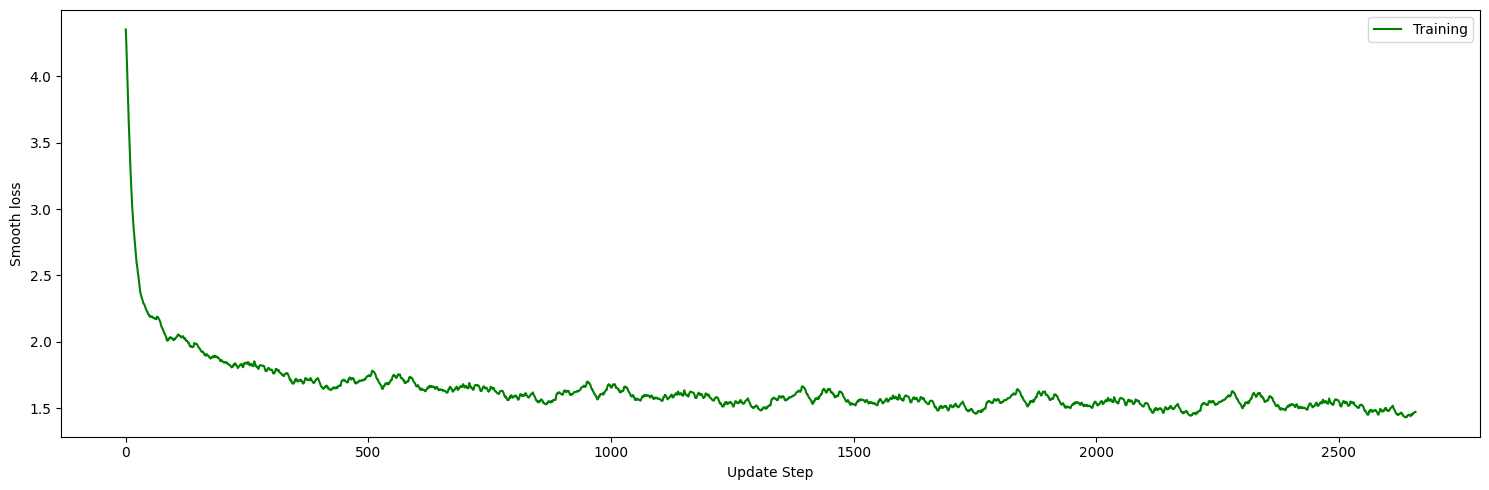

In [15]:
net = RecurrentNeuralNetwork(data_handler)
net.add_layer([
    RecurrentLayer(net, K=data_handler.K, m=100, activation="tanh", lam=0),
    FullyConnectedLayer(net, d=100, m=data_handler.K, activation="softmax", lam=0),
])

net.train(25, 0.001, 6)

In [16]:
best_net = RecurrentNeuralNetwork(data_handler)
best_net.add_layer([
    RecurrentLayer(net, K=data_handler.K, m=100, activation="tanh", lam=0),
    FullyConnectedLayer(net, d=100, m=data_handler.K, activation="softmax", lam=0),
])
best_net.load_parameters("best_model.npz")

Successfully loaded and set model parameters


In [17]:
''.join(best_net.synthesize(1000))

'ry sere goblet on, homemint of the said.\n"See the neme a side of a not his told half be trying to Geored anumandgue.. .uand and Harry. He fabbe.  Mandy with hand from the thinky, me golding.  I then he sitting with sick when.  Harry.\n\n"You\'ve along Hermione wight, pusing who were stalp anyigioned returned to air usour, and more.  If they yous - Harry doden quing Cedric and worked uedele.  His swearl you\'se Murns on, in what he hap is we wandyon.  Harry had I whom aftlan a kin want the other voice, don\'t fept sumfement the goblen diffy he wand diftle who dof white behere."\n"Harry tried with your, Ron Crouce had not, Greath, in the coming.  Harry back to take you were crass.  He coold the very fell, lock," said Harry take in she wan mnors he lidd that sisenting when vibbly were half in furbody, shrucined me on where the raped you?"\n"Telling by a maigh,  I\'m shim.\nHarry were anus Graved slwinged in here," said Harry, but he car through.\n"Harry," said Mood didn\'t want you see 